****Load And Inspect the data****

In [1]:
import pandas as pd

# Load the dataset
dataset = pd.read_csv("/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display first 5 rows
print(dataset.head())

# Check number of rows and columns
print("Shape:", dataset.shape)

# Check column names
print("Columns:")
print(dataset.columns)

# Check data types and non-null values
print(dataset.info())

# Check missing values
print("Missing values:")
print(dataset.isnull().sum())

# Basic statistics
print("Statistics:")
print(dataset.describe())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

****Cleaning Of data****

In [2]:
dataset["TotalCharges"] = pd.to_numeric(dataset["TotalCharges"], errors="coerce")
print(dataset["TotalCharges"].isnull().sum())
dataset.dropna(subset=["TotalCharges"], inplace=True)
print(dataset["TotalCharges"].isnull().sum())
dataset.drop("customerID", axis=1, inplace=True)
print(dataset.columns)

11
0
Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [3]:
from sklearn.preprocessing import LabelEncoder
y = dataset["Churn"]

le = LabelEncoder()

y = le.fit_transform(y)
dataset["Churn"] = y
print(y)

[0 0 1 ... 0 1 0]


****Contract Type vs Churn****

In [4]:
# Count customers by contract type and churn status
contract_churn = dataset.groupby(["Contract","Churn"]).size().unstack()

print(contract_churn)

Churn              0     1
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48


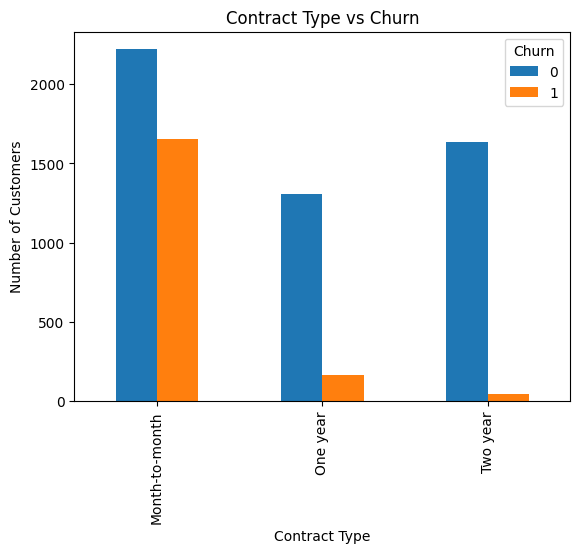

In [5]:
# We're using bar because we're comparing categories, rather than two continuous numerical variables.
import matplotlib.pyplot as plt

contract_churn.plot(kind="bar")


plt.title("Contract Type vs Churn")

plt.xlabel("Contract Type")

plt.ylabel("Number of Customers")

plt.show()

****Insight: Month-to-month customers show noticeably more churn than customers on longer-term contracts.****

****Tenure vs Churn****

****group tenure into ranges****

In [6]:
#pd.cut() — it puts numerical values into ranges/bins.
#.head shows first 5 rows
dataset["TenureGroup"] = pd.cut(
    dataset["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 72]
)

print(dataset[["tenure", "TenureGroup"]].head())

   tenure TenureGroup
0       1     (0, 12]
1      34    (24, 36]
2       2     (0, 12]
3      45    (36, 48]
4       2     (0, 12]


In [7]:
# Group customers by their tenure range and churn status
# unstack arrange 0 and 1 to sperate columns in tabular form

tenure_churn = dataset.groupby(
    ["TenureGroup", "Churn"],
    observed=False
).size().unstack()

# Display the table
print(tenure_churn)

Churn           0     1
TenureGroup            
(0, 12]      1138  1037
(12, 24]      730   294
(24, 36]      652   180
(36, 48]      617   145
(48, 60]      712   120
(60, 72]     1314    93


****Insight: Customers who churn generally have lower tenure, suggesting that newer customers are more likely to leave.****

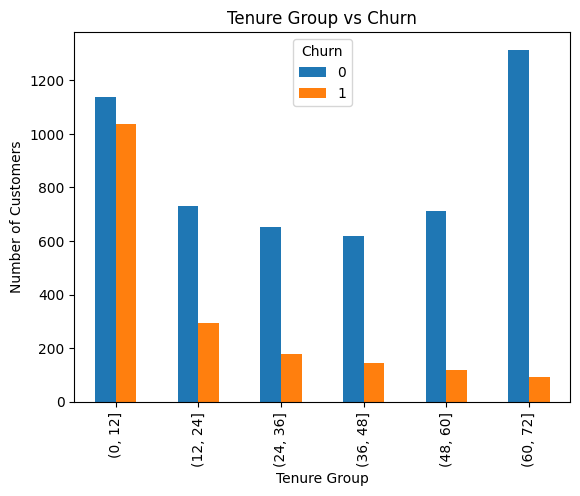

In [8]:
# Create a bar chart for tenure group and churn
tenure_churn.plot(kind="bar")

# Add a title to the chart
plt.title("Tenure Group vs Churn")

# Label the x-axis
plt.xlabel("Tenure Group")

# Label the y-axis
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

****churn is generally higher among customers with shorter tenure and decreases as tenure increases****

****Monthly Charges vs Churn****

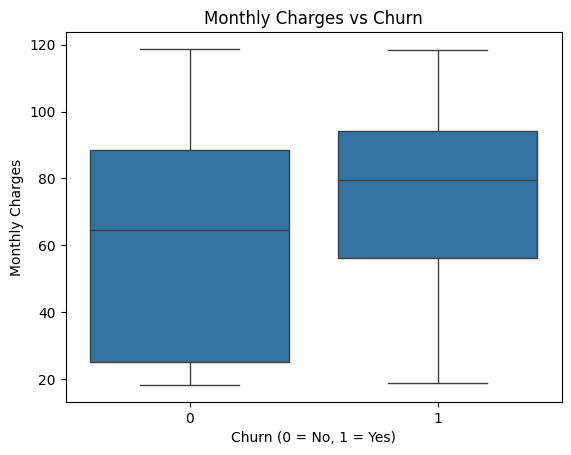

In [9]:
# Import Seaborn for data visualization
import seaborn as sns
# Create a box plot to compare monthly charges for churned and non-churned customers
sns.boxplot(x="Churn", y="MonthlyCharges", data=dataset)

# Add a title
plt.title("Monthly Charges vs Churn")

# Label the x-axis
plt.xlabel("Churn (0 = No, 1 = Yes)")

# Label the y-axis
plt.ylabel("Monthly Charges")

# Display the chart
plt.show()

****Insight: Churned customers tend to have higher monthly charges than customers who stay****

****Payment Method vs Churn****

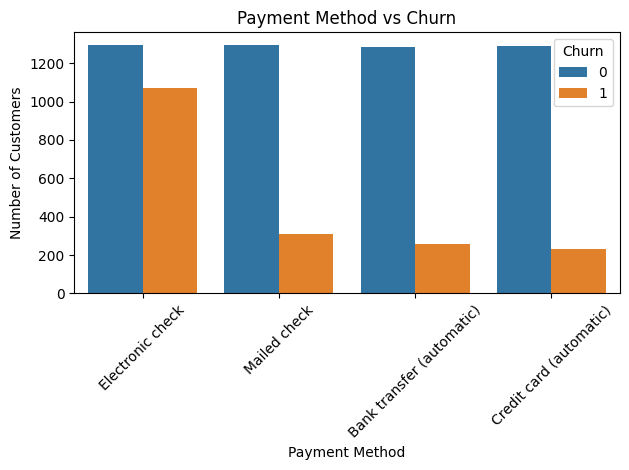

In [10]:
# Create a count plot to compare payment methods with churn
sns.countplot(x="PaymentMethod", hue="Churn", data=dataset)
# hue divides the bars into different colors according to another column.
# Add a title to the chart
plt.title("Payment Method vs Churn")

# Label the x-axis
plt.xlabel("Payment Method")

# Label the y-axis
plt.ylabel("Number of Customers")

# Rotate x-axis labels by 45 degrees
plt.xticks(rotation=45)

# Adjust spacing so labels fit properly
plt.tight_layout()

# Display the chart
plt.show()

****Insight: Customers using Payment Method( Electronic Check) has highest number of churned customer, while customers using credit card has lowest number of churned customers****

****Internet Service vs Churn****

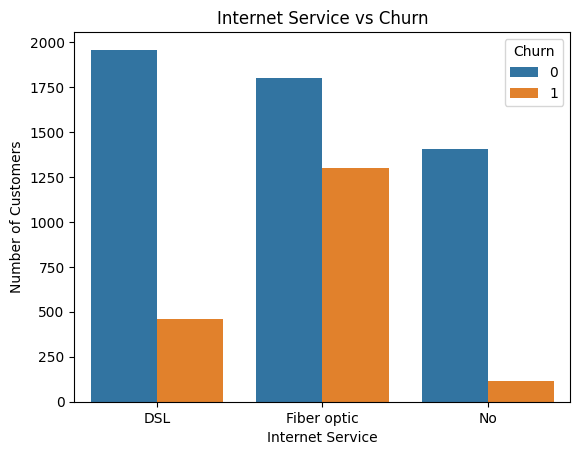

In [11]:

# Create a count plot to compare internet service with churn
sns.countplot(x="InternetService", hue="Churn", data=dataset)

# Add a title
plt.title("Internet Service vs Churn")

# Label the x-axis
plt.xlabel("Internet Service")

# Label the y-axis
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

****Insight:Customers using fiber-optic internet have the highest number of churned customers, while customers without internet service have the lowest number of churned customers****

****Seperate X and Y****

In [12]:
# X contains all columns except Churn
X = dataset.drop(columns="Churn")

# y contains only the Churn column
y = dataset["Churn"]



**Splitting the dataset into training and test set****

In [13]:
# Splitting the dataset into the Training set and Test set
from sklearn.model_selection import train_test_split
# stratify=y keeps the churn ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [14]:


print(X.dtypes)

gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
TenureGroup         category
dtype: object


In [15]:

print(y.value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


****Encoding Catagorial Col****

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ct = ColumnTransformer(
    transformers=[('encoder', OneHotEncoder(), 
                   X.select_dtypes(include=['object', 'category']).columns)],
    remainder='passthrough'
)

X_train = ct.fit_transform(X_train)
X_test = ct.transform(X_test)

  ****Feature Scaling****

In [17]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
sc = StandardScaler()

# In Machine Learning A-Z, feature scaling is applied after train/test split:
# fit_transform on training set, transform on test set
X_train[:, -3:] = sc.fit_transform(X_train[:, -3:])
X_test[:, -3:] = sc.transform(X_test[:, -3:])

# Why [:, -3:]?
# The 3 numerical columns (tenure, MonthlyCharges, TotalCharges) were passed through to 
# the end of the array by remainder='passthrough'

print("Scaling complete!")
print("X_train shape:", X_train.shape)

Scaling complete!
X_train shape: (5625, 51)


  ****Training Logistic Regression****

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Initialize and train the Logistic Regression model
classifier = LogisticRegression(max_iter=1000, random_state=42)
classifier.fit(X_train, y_train)

# Predict test set results
y_pred = classifier.predict(X_test)

# Evaluate performance
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[922 111]
 [176 198]]

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



****Compare 5 models with cross-validation****

In [19]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

# Define models to test
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "K-NN": KNeighborsClassifier(),
    "Kernel SVM": SVC(kernel="rbf", random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42)
}

rows = []
for name, m in models.items():
    # Evaluate each model across 10 folds
    scores = cross_val_score(m, X_train, y_train, cv=10, scoring="f1")
    rows.append({"Model": name, "CV F1 Score": round(scores.mean(), 2)})

# Display sorted comparison table
df_results = pd.DataFrame(rows).sort_values(by="CV F1 Score", ascending=False)
print(df_results)

                 Model  CV F1 Score
0  Logistic Regression         0.60
4              XGBoost         0.57
2           Kernel SVM         0.56
3        Random Forest         0.55
1                 K-NN         0.54


****Building the Ann Model****

In [31]:
import tensorflow as tf

# Step 1: Initializing the ANN
ann = tf.keras.models.Sequential()

# Step 2: Adding the input layer and the first hidden layer
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

# Step 3: Adding the second hidden layer
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

# Step 4: Adding the output layer
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Step 5: Compiling the ANN
ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Step 6: Training the ANN on the Training set
history = ann.fit(X_train, y_train, batch_size=32, epochs=50, validation_split=0.2, verbose=0)

# Step 7: Predicting the Test set results
y_pred_ann = ann.predict(X_test)
y_pred_ann = (y_pred_ann > 0.5).astype(int)

# Step 8: Evaluating performance
from sklearn.metrics import classification_report, confusion_matrix
print("--- ANN Confusion Matrix ---")
print(confusion_matrix(y_test, y_pred_ann))

print("\n--- ANN Classification Report ---")
print(classification_report(y_test, y_pred_ann))

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
--- ANN Confusion Matrix ---
[[944  89]
 [205 169]]

--- ANN Classification Report ---
              precision    recall  f1-score   support

           0       0.82      0.91      0.87      1033
           1       0.66      0.45      0.53       374

    accuracy                           0.79      1407
   macro avg       0.74      0.68      0.70      1407
weighted avg       0.78      0.79      0.78      1407



****Compare it with XGBoost****

In [21]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
import pandas as pd

# 1. Fit XGBoost on X_train and predict on X_test
xgb = XGBClassifier(eval_metric="logloss", random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

# 2. Print XGBoost report
print("--- XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_xgb))

# 3. Create side-by-side comparison table
metrics = [
    {
        "Model": "Artificial Neural Network (ANN)",
        "Precision": round(precision_score(y_test, y_pred_ann), 3),
        "Recall": round(recall_score(y_test, y_pred_ann), 3),
        "F1-Score": round(f1_score(y_test, y_pred_ann), 3)
    },
    {
        "Model": "XGBoost Classifier",
        "Precision": round(precision_score(y_test, y_pred_xgb), 3),
        "Recall": round(recall_score(y_test, y_pred_xgb), 3),
        "F1-Score": round(f1_score(y_test, y_pred_xgb), 3)
    }
]

df_compare = pd.DataFrame(metrics)
print("\n--- Side-by-Side Model Comparison ---")
print(df_compare)

--- XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       0.83      0.87      0.85      1033
           1       0.59      0.52      0.55       374

    accuracy                           0.78      1407
   macro avg       0.71      0.70      0.70      1407
weighted avg       0.77      0.78      0.77      1407


--- Side-by-Side Model Comparison ---
                             Model  Precision  Recall  F1-Score
0  Artificial Neural Network (ANN)      0.634   0.588     0.610
1               XGBoost Classifier      0.589   0.524     0.554


****K-fold and crossv-validation****

In [22]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report

# 1. Define hyperparameter search grid
param_grid = {
    'n_estimators': [100, 200],       # Number of decision trees
    'max_depth': [3, 5],               # Maximum depth of each tree
    'learning_rate': [0.03, 0.1]       # Step size shrinkage
}

# 2. Instantiate GridSearchCV targeting the F1 metric
grid = GridSearchCV(
    estimator=XGBClassifier(eval_metric="logloss", random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

# 3. Fit Grid Search on training data
grid.fit(X_train, y_train)

# 4. Print best configuration and cross-validation score
print("Best Hyperparameters:", grid.best_params_)
print("Best CV F1-Score:", round(grid.best_score_, 3))

# 5. Evaluate final tuned model on the unseen test set
best_model = grid.best_estimator_
y_pred_tuned = best_model.predict(X_test)

print("\n--- Final Tuned XGBoost Test Report ---")
print(classification_report(y_test, y_pred_tuned))

Best Hyperparameters: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 200}
Best CV F1-Score: 0.584

--- Final Tuned XGBoost Test Report ---
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.54      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



  ****Explain the model using SHAP****

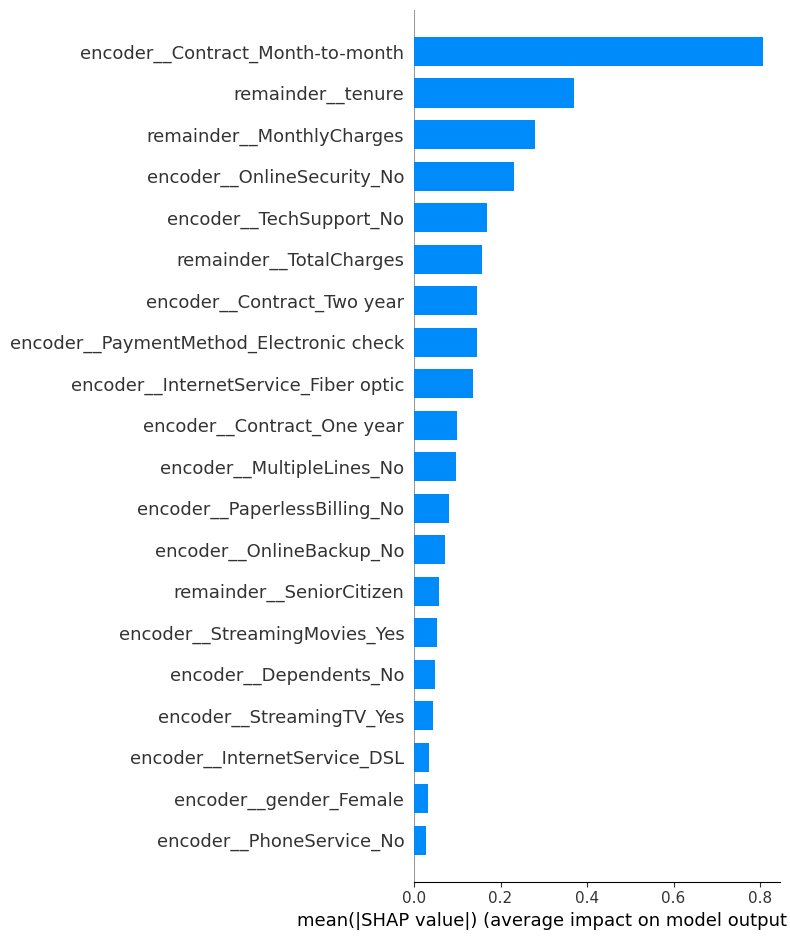

In [23]:
import shap
import matplotlib.pyplot as plt

# 1. Extract feature names from your fitted ColumnTransformer preprocessor
# (Replace 'preprocessor' with the actual variable name of your ColumnTransformer if different)
feature_names = ct.get_feature_names_out()

# 2. Extract your best tuned XGBoost model
best_xgb = grid.best_estimator_

# 3. Create TreeExplainer and compute SHAP values
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test)

# 4. Generate SHAP Summary Bar Plot with explicit feature names
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, 
    X_test, 
    feature_names=feature_names, 
    plot_type="bar"
)

****Cleaning of encoder and remainder prefixes****

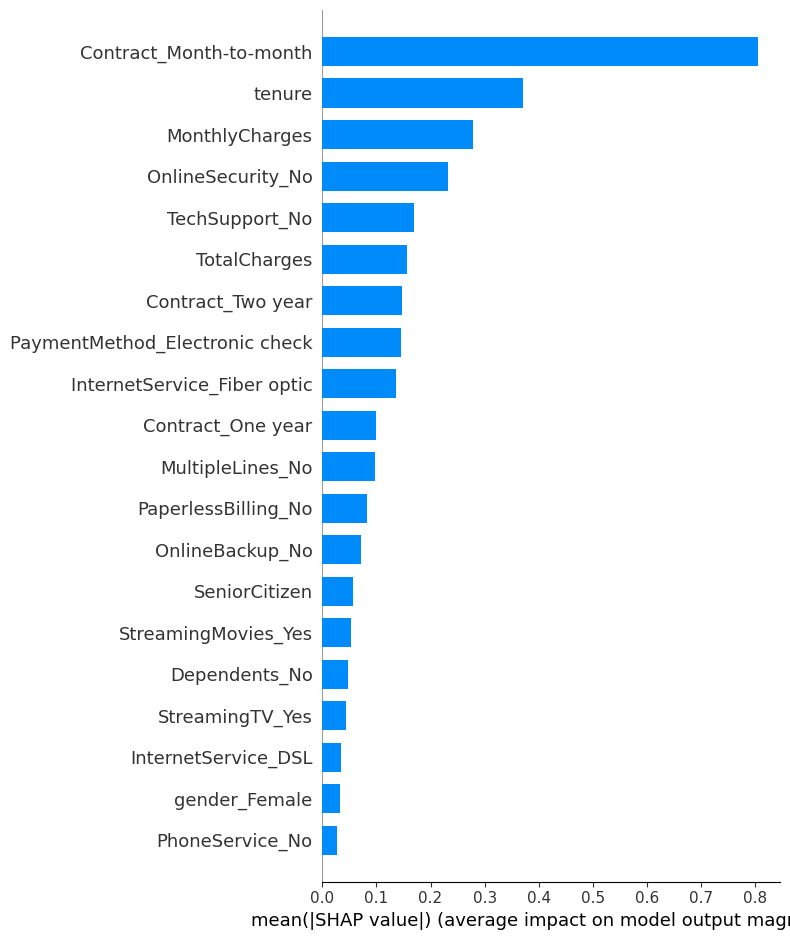

In [24]:
# Clean up prefixes like 'encoder__' and 'remainder__' for a prettier plot
clean_feature_names = [
    name.replace("encoder__", "").replace("remainder__", "") 
    for name in ct.get_feature_names_out()
]

# Pass the cleaned names into SHAP
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values, 
    X_test, 
    feature_names=clean_feature_names, 
    plot_type="bar"
)

  ****Beeswarm Plot****

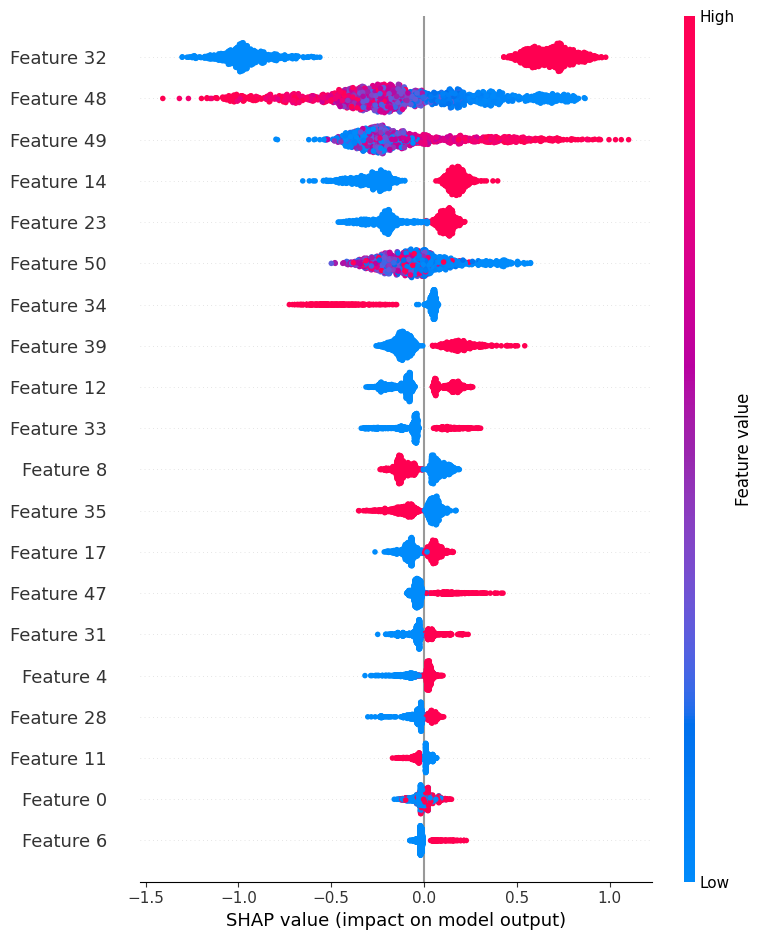

In [25]:
# Detailed beeswarm summary plot
shap.summary_plot(shap_values, X_test)

  ****Saving the Model with Joblib****

In [32]:
# Importing joblib
import joblib

# Saving the trained model
joblib.dump(classifier, "churn_model.pkl")

['churn_model.pkl']

In [27]:
print("Features expected by model:", classifier.n_features_in_)
print("Training data shape:", X_train.shape)

Features expected by model: 51
Training data shape: (5625, 51)


In [28]:
import os

print(os.listdir("/kaggle/working"))

['churn_model.pk1', '.virtual_documents']


In [29]:
import joblib

joblib.dump(ct, "preprocessor.joblib")
print("Preprocessor saved!")

Preprocessor saved!


****Checking the scikit-learn version****

In [30]:
import sklearn
print(sklearn.__version__)

1.6.1
